# Étude de cas : réduire la dépense achats de 5 %
**Question de la directrice Achats :** où regarder en priorité, combien peut-on économiser, et avec quel niveau de confiance ?

**Données :** commandes de Californie, exercices 2012-2013 à 2014-2015. Tous les montants sont en dollars courants historiques.

**Plan :** 1–3. Qualité des données · 4. Périmètre et objectif · 5. Priorités · 6. Prix comparables · 7. Scénarios d'économies · 8. Décisions et suivi.

**Convention essentielle :** « dépense » désigne ici un **montant net de commandes enregistrées**, et non une dépense comptable payée. Les commandes peuvent engager plusieurs années. Les bases annuelles sont des proxys historiques, pas des budgets prévisionnels. L'« an prochain » de l'exercice est traité comme l'année suivant la dernière observation ; aucune projection pour 2027 n'est possible avec ce fichier.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

## 1. Chargement et premier regard

**Intérêt :** vérifier que le fichier contient bien ce qu'annonce l'énoncé (taille, colonnes, types) avant de nettoyer.

`df_raw` = données d'origine, jamais modifiées. Le nettoyage se fait sur une copie `df`.

In [2]:
# Le CSV n'est pas inclus dans le rendu. Déposer le fichier original à côté du notebook,
# dans data/, ou renseigner la variable d'environnement ACHATS_CSV.
import os
candidats = [Path(os.environ.get("ACHATS_CSV", "purchase-order-data-2012-2015-.csv")),
             Path("data/purchase-order-data-2012-2015-.csv"),
             Path("../data/purchase-order-data-2012-2015-.csv")]
CSV_PATH = next((p for p in candidats if p.is_file()), None)
if CSV_PATH is None:
    raise FileNotFoundError("Déposer le CSV original à côté du notebook ou définir ACHATS_CSV.")
df_raw = pd.read_csv(CSV_PATH, encoding="utf-8", low_memory=False)

In [3]:
df_raw.shape

(344504, 32)

In [4]:
df_raw.head()

,Creation Date,Purchase Date,Fiscal Year,LPA Number,Purchase Order Number,Requisition Number,Acquisition Type,Sub-Acquisition Type,Acquisition Method,Sub-Acquisition Method,Department Name,Supplier Code,Supplier Name,Supplier Qualifications,Supplier Zip Code,CalCard,Item Name,Item Description,Quantity,Unit Price,Total Price,Classification Codes,Normalized UNSPSC,Commodity Title,Class,Class Title,Family,Family Title,Segment,Segment Title,Location,REMOVE AMERISOURCE
0,8/27/2013,NaN,2013-2014,7-12-70-26,REQ0011118,REQ0011118,IT Goods,NaN,WSCA/Coop,NaN,"Consumer Affairs, Department of",1740272.0,Pitney Bowes,NaN,NaN,NO,USB,USB,1.0,$1.00,$1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1/29/2014,NaN,2013-2014,NaN,REQ0011932,REQ0011932,NON-IT Goods,NaN,Informal Competitive,NaN,"Consumer Affairs, Department of",1760085.0,Rodea Auto Tech,NaN,NaN,NO,Tire Disposal,Tire Disposal,2.0,$2.00,$4.00,76121504,76121504.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11/1/2013,NaN,2013-2014,NaN,REQ0011476,REQ0011476,IT Services,NaN,Informal Competitive,NaN,"Consumer Affairs, Department of",17224.0,"Smile Business Products, Inc",NaN,95841,NO,Labor,Labor,4.5,$150.00,$675.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"95841\n(38.662263, -121.346136)",NaN
3,6/13/2014,6/5/2014,2013-2014,NaN,4500236642,NaN,NON-IT Goods,NaN,Informal Competitive,NaN,Correctional Health Care Services,1754462.0,ASHAN INC,CA-MB CA-SB,91436,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"91436\n(34.151642, -118.49051)",NaN
4,3/12/2014,3/12/2014,2013-2014,1-10-75-60A,4500221028,NaN,NON-IT Goods,NaN,Statewide Contract,NaN,"Corrections and Rehabilitation, Department of",1087660.0,Technology Integration Group,NaN,95814,NO,Toner,Toner,1.0,"$6,080.26","$6,080.26",44103127,44103127.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"95814\n(38.580427, -121.494396)",NaN


In [5]:
df_raw.dtypes

Creation Date                  str
Purchase Date                  str
Fiscal Year                    str
LPA Number                     str
Purchase Order Number          str
Requisition Number             str
Acquisition Type               str
Sub-Acquisition Type           str
Acquisition Method             str
Sub-Acquisition Method         str
Department Name                str
Supplier Code              float64
Supplier Name                  str
Supplier Qualifications        str
Supplier Zip Code              str
CalCard                        str
Item Name                      str
Item Description               str
Quantity                   float64
Unit Price                     str
Total Price                    str
Classification Codes           str
Normalized UNSPSC          float64
Commodity Title                str
Class                      float64
Class Title                    str
Family                     float64
Family Title                   str
Segment             

**Interprétation :** 344 504 lignes et 32 colonnes, conformes à l'énoncé. Une ligne = un article d'une commande. `Unit Price` et `Total Price` sont du texte alors qu'ils devraient être des nombres : c'est le premier point à traiter.

## 2. Nettoyage

### 2.1 Prix : conversion du texte en nombres

**Intérêt :** tant que les prix sont du texte, on ne peut ni les additionner ni les comparer. On commence par repérer tous les formats présents dans les colonnes, au lieu de se fier aux 5 premières lignes.

In [6]:
df_raw["Total Price"].sample(10, random_state=1)

166604    $498,000.00 
83314      $39,543.96 
153682        $156.49 
258912      $8,000.00 
38152           $8.47 
137519      $5,208.00 
171177     $11,424.00 
130478     $11,500.00 
45221           $0.00 
229868         $77.28 
Name: Total Price, dtype: str

In [7]:
forme_total = df_raw["Total Price"].dropna().str.replace(r"\d+", "x", regex=True)
forme_total.value_counts()

Total Price
$x,x.x         209477
$x.x           128098
$x,x,x.x         5436
($x,x.x)          726
($x.x)            692
$x,x,x,x.x         25
($x,x,x.x)         20
Name: count, dtype: int64

In [8]:
forme_unit = df_raw["Unit Price"].dropna().str.replace(r"\d+", "x", regex=True)
forme_unit.value_counts()

Unit Price
$x.x           186086
$x,x.x         151632
$x,x,x.x         5293
($x.x)            818
($x,x.x)          600
$x,x,x,x.x         25
($x,x,x.x)         20
Name: count, dtype: int64

In [9]:
print("Lignes dans le fichier :", len(df_raw))
print("Prix vides             :", df_raw["Total Price"].isna().sum())
print("Prix négatifs          :", df_raw["Total Price"].str.startswith("(").sum())
print("Prix avec une forme    :", forme_total.value_counts().sum())

Lignes dans le fichier : 344504
Prix vides             : 30
Prix négatifs          : 1438
Prix avec une forme    : 344474


In [10]:
print("Lignes dans le fichier :", len(df_raw))
print("Prix vides             :", df_raw["Unit Price"].isna().sum())
print("Prix négatifs          :", df_raw["Unit Price"].str.startswith("(").sum())
print("Prix avec une forme    :", forme_unit.value_counts().sum())

Lignes dans le fichier : 344504
Prix vides             : 30
Prix négatifs          : 1438
Prix avec une forme    : 344474


**Interprétation :** `Unit Price` et `Total Price` sont du texte (`$498,000.00`). Les négatifs sont entre parenthèses (notation comptable).

**Décision :** convertir en nombres (retirer `$`, virgules et espaces ; parenthèses = négatif). La fonction est testée sur des cas connus avant d'être appliquée.

In [11]:
def parse_money(series):
    est_negatif = series.str.startswith("(").fillna(False).astype(bool)
    nombres = pd.to_numeric(
        series.str.replace(r"[()$,\s]", "", regex=True), errors="coerce"
    )
    return nombres.where(~est_negatif, -nombres)

In [12]:
test = pd.Series(["$675.00 ", "$1,118.60 ", "($7.00)", None])
resultat = parse_money(test)
print(resultat.tolist())
assert resultat.iloc[:3].tolist() == [675.0, 1118.6, -7.0]
assert pd.isna(resultat.iloc[3])

[675.0, 1118.6, -7.0, nan]


In [13]:
df = df_raw.copy()

for col in ["Unit Price", "Total Price"]:
    df[col] = parse_money(df[col])
    assert df[col].isna().sum() == df_raw[col].isna().sum(), f"Valeurs perdues dans {col}"

In [14]:
df.head()

,Creation Date,Purchase Date,Fiscal Year,LPA Number,Purchase Order Number,Requisition Number,Acquisition Type,Sub-Acquisition Type,Acquisition Method,Sub-Acquisition Method,Department Name,Supplier Code,Supplier Name,Supplier Qualifications,Supplier Zip Code,CalCard,Item Name,Item Description,Quantity,Unit Price,Total Price,Classification Codes,Normalized UNSPSC,Commodity Title,Class,Class Title,Family,Family Title,Segment,Segment Title,Location,REMOVE AMERISOURCE
0,8/27/2013,NaN,2013-2014,7-12-70-26,REQ0011118,REQ0011118,IT Goods,NaN,WSCA/Coop,NaN,"Consumer Affairs, Department of",1740272.0,Pitney Bowes,NaN,NaN,NO,USB,USB,1.0,1.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1/29/2014,NaN,2013-2014,NaN,REQ0011932,REQ0011932,NON-IT Goods,NaN,Informal Competitive,NaN,"Consumer Affairs, Department of",1760085.0,Rodea Auto Tech,NaN,NaN,NO,Tire Disposal,Tire Disposal,2.0,2.00,4.00,76121504,76121504.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11/1/2013,NaN,2013-2014,NaN,REQ0011476,REQ0011476,IT Services,NaN,Informal Competitive,NaN,"Consumer Affairs, Department of",17224.0,"Smile Business Products, Inc",NaN,95841,NO,Labor,Labor,4.5,150.00,675.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"95841\n(38.662263, -121.346136)",NaN
3,6/13/2014,6/5/2014,2013-2014,NaN,4500236642,NaN,NON-IT Goods,NaN,Informal Competitive,NaN,Correctional Health Care Services,1754462.0,ASHAN INC,CA-MB CA-SB,91436,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"91436\n(34.151642, -118.49051)",NaN
4,3/12/2014,3/12/2014,2013-2014,1-10-75-60A,4500221028,NaN,NON-IT Goods,NaN,Statewide Contract,NaN,"Corrections and Rehabilitation, Department of",1087660.0,Technology Integration Group,NaN,95814,NO,Toner,Toner,1.0,6080.26,6080.26,44103127,44103127.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"95814\n(38.580427, -121.494396)",NaN


In [15]:
print("Prix négatifs :", (df["Total Price"] < 0).sum())
print(f"Dépense totale : {df['Total Price'].sum():,.0f} $")

Prix négatifs : 1438
Dépense totale : 150,517,871,463 $


**Contrôles :** aucun prix perdu (le nombre de vides est resté identique) et les 1 438 négatifs sont retrouvés. Dépense totale de référence : 150 517 871 463 $. Chaque nettoyage suivant sera comparé à ce chiffre.

### 2.2 Structure des colonnes

**Intérêt :** repérer les colonnes vides ou presque vides, puis standardiser les noms de colonnes pour simplifier le code.

In [16]:
df.isna().mean().sort_values(ascending=False)

REMOVE AMERISOURCE         1.000000
Requisition Number         0.958299
Sub-Acquisition Method     0.910355
Sub-Acquisition Type       0.801645
LPA Number                 0.736151
Supplier Qualifications    0.588553
Location                   0.203423
Supplier Zip Code          0.203423
Purchase Date              0.050568
Family                     0.009559
Family Title               0.009559
Class Title                0.009559
Segment Title              0.009559
Commodity Title            0.009559
Class                      0.009559
Segment                    0.009559
Normalized UNSPSC          0.002952
Classification Codes       0.002952
Item Description           0.000583
Supplier Code              0.000104
Supplier Name              0.000104
Item Name                  0.000093
Quantity                   0.000087
Total Price                0.000087
Unit Price                 0.000087
CalCard                    0.000000
Acquisition Method         0.000000
Department Name            0

**Interprétation et décision :** `REMOVE AMERISOURCE` est vide à 100 % : supprimée. Les autres colonnes très vides (`Requisition Number` 96 %, `Sub-Acquisition Method` 91 %...) sont gardées : elles renseignent les lignes où elles sont remplies.

In [17]:
df = df.drop(columns=["REMOVE AMERISOURCE"])

**Nom des colonnes**

**Décision :** les noms passent en `snake_case` (minuscules, underscores) pour simplifier le code. `df_raw` garde les noms d'origine.

In [18]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)
assert df.shape == (len(df_raw), 31), "Forme inattendue"
df.columns.tolist()

['creation_date',
 'purchase_date',
 'fiscal_year',
 'lpa_number',
 'purchase_order_number',
 'requisition_number',
 'acquisition_type',
 'sub_acquisition_type',
 'acquisition_method',
 'sub_acquisition_method',
 'department_name',
 'supplier_code',
 'supplier_name',
 'supplier_qualifications',
 'supplier_zip_code',
 'calcard',
 'item_name',
 'item_description',
 'quantity',
 'unit_price',
 'total_price',
 'classification_codes',
 'normalized_unspsc',
 'commodity_title',
 'class',
 'class_title',
 'family',
 'family_title',
 'segment',
 'segment_title',
 'location']

### 2.3 Doublons exacts (identiques sur toutes les colonnes)

**Intérêt :** un achat saisi deux fois fausserait la dépense. On compte les lignes identiques et on chiffre leur impact avant de décider.

In [19]:
assert len(df) == len(df_raw), "Des lignes ont déjà été supprimées : relancer le notebook"

masque_doublons = df.duplicated()
montant = df.loc[masque_doublons, "total_price"].sum()

print("Lignes en doublon :", masque_doublons.sum())
print(f"Montant concerné  : {montant:,.0f} $ ({montant / df['total_price'].sum():.2%} de la dépense)")

Lignes en doublon : 2087
Montant concerné  : 59,874,850 $ (0.04% de la dépense)


In [20]:
doublons = df[df.duplicated(keep=False)]
tailles = doublons.groupby(list(df.columns), dropna=False).size()

print("Groupes de doublons :", len(tailles))
print(tailles.value_counts().sort_index().head(6))

Groupes de doublons : 1305
2    1015
3     135
4      65
5      41
6      16
7       7
Name: count, dtype: int64


**Test de concentration :** parmi les lignes avec doublon, quelle est la taille typique de leur commande ? Et parmi les lignes sans doublon ?

In [21]:
lignes_par_commande = df.groupby("purchase_order_number")["purchase_order_number"].transform("size")
dans_un_groupe = df.duplicated(keep=False)

print("Lignes par commande (médiane), doublons :", lignes_par_commande[dans_un_groupe].median())
print("Lignes par commande (médiane), autres   :", lignes_par_commande[~dans_un_groupe].median())

Lignes par commande (médiane), doublons : 15.0
Lignes par commande (médiane), autres   : 2.0


In [22]:
total_avec = df["total_price"].sum()
total_sans = df.loc[~masque_doublons, "total_price"].sum()

print(f"Avec doublons : {total_avec:,.0f} $")
print(f"Sans doublons : {total_sans:,.0f} $")
print(f"Écart         : {total_avec - total_sans:,.0f} $ ({(total_avec - total_sans) / total_avec:.2%})")

Avec doublons : 150,517,871,463 $
Sans doublons : 150,457,996,614 $
Écart         : 59,874,850 $ (0.04%)


**Interprétation :** 2 087 lignes répètent exactement des lignes précédentes, soit 0,04 % de la dépense. Les groupes sont surtout des paires, mais les doublons se concentrent dans de grosses commandes (médiane 15 lignes contre 2), ce qui évoque aussi des achats répétés.

**Décision :** je garde les doublons. Le CSV n'a pas de numéro de ligne : impossible de savoir s'il s'agit d'une double saisie ou d'un achat répété, et l'impact est négligeable dans les deux cas. Dans le doute, je ne supprime aucune ligne.

### 2.4 Prix à 0 et prix négatifs

**Intérêt :** un prix négatif réduit la dépense, un prix à 0 n'est pas un vrai prix. Que représentent ces lignes, et faut-il les garder ?

In [23]:
total = df["total_price"]

print("Prix à 0      :", (total == 0).sum())
print("Prix négatifs :", (total < 0).sum())
print(f"Somme des négatifs : {total[total < 0].sum():,.0f} $")

Prix à 0      : 7511
Prix négatifs : 1438
Somme des négatifs : -171,776,032 $


In [24]:
colonnes = ["department_name", "item_name", "quantity", "unit_price", "total_price"]

df.loc[total == 0, colonnes].sample(8, random_state=1)

,department_name,item_name,quantity,unit_price,total_price
38431,"Health Care Services, Department of",12-89308 A01,1.0,0.0,0.0
184115,"Water Resources, Department of",Amendment 14 for time only,1.0,0.0,0.0
13434,"Consumer Affairs, Department of",Software Image for VCS with Encryption Version...,1.0,0.0,0.0
267450,"State Hospitals, Department of",Electronic SW License for C3850 Switches,12.0,0.0,0.0
311703,Correctional Health Care Services,GlobalMed Exam Stn,2.0,0.0,0.0
236469,"Water Resources, Department of","CHARGER,RAPID F70/F80",4.0,0.0,0.0
176442,"State Hospitals, Department of",Dimension Enzyme,1.0,0.0,0.0
232634,"Health Care Services, Department of",05-45699 A07,1.0,0.0,0.0


In [25]:
df.loc[total < 0, colonnes].sample(8, random_state=1)

,department_name,item_name,quantity,unit_price,total_price
206856,"Public Health, Department of",10-95249 A01,1.0,-886.00,-886.00
293939,"Public Health, Department of",Office Furniture,1.0,-2369.00,-2369.00
213507,"Forestry and Fire Protection, Department of",MX-FNX9 INNER FINISHER/STAPLER,1.0,-534.01,-534.01
197023,"General Services, Department of",C.O. 024,1.0,-2700.00,-2700.00
194949,"Conservation, Department of",Trade-In - Catalyst 4507R Series Modular Switc...,1.0,-5661.45,-5661.45
13442,"Public Health, Department of","The Regents of the University of California, S...",1.0,-997752.00,-997752.00
190196,"Conservation, Department of",Trade-In - Catalyst 4507R Series Modular Switc...,1.0,-7197.63,-7197.63
55368,"Forestry and Fire Protection, Department of","15.6"" LED HD+ WVA AG",1.0,-82.16,-82.16


In [26]:
negatifs = df[total < 0]

print("Quantité négative :", (negatifs["quantity"] < 0).sum())

commandes_avec_achats = set(df.loc[total > 0, "purchase_order_number"])
part = negatifs["purchase_order_number"].isin(commandes_avec_achats).mean()
print(f"Négatifs situés dans une commande qui a aussi des lignes positives : {part:.0%}")

Quantité négative : 0
Négatifs situés dans une commande qui a aussi des lignes positives : 100%


In [27]:
zeros = df[total == 0]

print("Quantité > 0      :", (zeros["quantity"] > 0).mean())
print("Prix unitaire à 0 :", (zeros["unit_price"] == 0).mean())

Quantité > 0      : 1.0
Prix unitaire à 0 : 0.9998668619358274


**Interprétation et décision :**
- **Prix négatifs** : la quantité n'est jamais négative, le signe vient du prix. Ils sont tous dans des commandes qui contiennent aussi des achats positifs : ce sont des ajustements à la baisse de commandes existantes. **Je les garde** : la dépense réelle est un montant net.
- **Prix à 0** : ce sont de vrais articles (quantité > 0) avec un prix unitaire à 0. Sans effet sur les sommes. **Je les garde.**
- Pour les futures comparaisons de prix unitaires, ces deux familles seront exclues (un prix négatif ou nul n'est pas un prix d'achat comparable). Aucune suppression à ce stade.

### 2.5 Valeurs manquantes (colonnes clés)

**Intérêt :** savoir quelles colonnes essentielles (département, fournisseur, commande, article, quantité, prix) sont incomplètes, et quelle part de la dépense est concernée.

In [28]:
colonnes_cles = ["department_name", "supplier_name", "supplier_code", "purchase_order_number",
                 "item_name", "quantity", "unit_price", "total_price",
                 "fiscal_year", "normalized_unspsc", "purchase_date"]

manquants = pd.DataFrame({
    "manquants": df[colonnes_cles].isna().sum(),
    "pourcentage": (df[colonnes_cles].isna().mean() * 100).round(3),
})
manquants.sort_values("manquants", ascending=False)

,manquants,pourcentage
purchase_date,17421,5.057
normalized_unspsc,1017,0.295
supplier_name,36,0.010
supplier_code,36,0.010
item_name,32,0.009
total_price,30,0.009
quantity,30,0.009
unit_price,30,0.009
department_name,0,0.000
purchase_order_number,0,0.000


In [29]:
# Les lignes sans prix : ont-elles aussi une quantité et un prix unitaire ?
sans_prix = df["total_price"].isna()
assert ((df["quantity"].isna() & df["unit_price"].isna()) == sans_prix).all()

print("Lignes sans prix                       :", sans_prix.sum())
print("Lignes sans prix et sans nom d'article :", df.loc[sans_prix, "item_name"].isna().sum())
print(df.loc[sans_prix, "department_name"].value_counts().to_string())

Lignes sans prix                       : 30
Lignes sans prix et sans nom d'article : 30
department_name
Correctional Health Care Services    30


In [30]:
# Les lignes sans fournisseur : quel montant ?
sans_fournisseur = df["supplier_name"].isna()
assert (sans_fournisseur == df["supplier_code"].isna()).all()   # nom et code manquent ensemble

montant = df.loc[sans_fournisseur, "total_price"].sum()
print("Lignes sans fournisseur :", sans_fournisseur.sum())
print(f"Montant concerné        : {montant:,.0f} $ ({montant / df['total_price'].sum():.3%} de la dépense)")

Lignes sans fournisseur : 36
Montant concerné        : 3,318,993 $ (0.002% de la dépense)


In [31]:
inconnu = df["supplier_name"].str.casefold() == "unknown"
montant = df.loc[inconnu, "total_price"].sum()

print("Lignes avec le fournisseur « Unknown » :", inconnu.sum())
print("Codes fournisseur de ces lignes        :", df.loc[inconnu, "supplier_code"].unique())
print(f"Montant concerné : {montant:,.0f} $ ({montant / df['total_price'].sum():.2%} de la dépense)")
(df.loc[inconnu].groupby("department_name")["total_price"].sum().nlargest(3) / 1e9).round(2)

Lignes avec le fournisseur « Unknown » : 4473
Codes fournisseur de ces lignes        : [0.]
Montant concerné : 2,993,348,097 $ (1.99% de la dépense)


department_name
High Speed Rail Authority, California            2.14
Corrections and Rehabilitation, Department of    0.12
Employment Development Department                0.07
Name: total_price, dtype: float64

**Interprétation :** les clés département, commande et exercice sont complètes. Les 30 lignes sans prix ne permettent pas de chiffrer un montant : une somme les ignore, ce qui ne prouve pas une dépense nulle. Aux 36 fournisseurs vides s'ajoutent **4 473 lignes libellées « Unknown »**, soit environ **2,99 Md$** : l'identité fournisseur est un enjeu matériel.

**Décision :** conserver les lignes et distinguer fournisseur identifié / non identifié ; ne jamais traiter « Unknown » comme un fournisseur réel.

### 2.6 Colonnes textuelles : espaces superflus et chaînes vides

**Intérêt :** des espaces en trop (`"Acme  Inc "`) créent de fausses valeurs distinctes et faussent les regroupements et les doublons. On les retire, **sans changer la casse et sans fusionner de noms** (fusionner des fournisseurs demande un jugement, pas un nettoyage mécanique). La colonne `location` est exclue : elle contient volontairement des retours à la ligne (adresse + coordonnées) et n'est pas utilisée.

In [32]:
colonnes_texte = [c for c in df.columns if (pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c])) and c != "location"]

def audit_espaces(serie):
    s = serie.dropna()
    return pd.Series({
        "espaces_en_bord": (s != s.str.strip()).sum(),
        "espaces_multiples": s.str.contains(r"\s{2,}").sum(),
        "chaines_vides": (s.str.strip() == "").sum(),
    })

audit = df[colonnes_texte].apply(audit_espaces).T
audit[(audit > 0).any(axis=1)]

,espaces_en_bord,espaces_multiples,chaines_vides
purchase_order_number,0,56,0
supplier_name,0,238,0
item_name,61,2673,0
item_description,161,24302,0


In [33]:
def normaliser_texte(serie):
    """Retire les espaces en début/fin et réduit les espaces multiples à un seul. Ne change pas la casse."""
    return serie.str.strip().str.replace(r"\s+", " ", regex=True)

# test sur un cas connu
test = normaliser_texte(pd.Series(["  Abc   Def ", None]))
assert test.iloc[0] == "Abc Def" and pd.isna(test.iloc[1])

distincts_avant = df[colonnes_texte].nunique()
for col in colonnes_texte:
    df[col] = normaliser_texte(df[col])
distincts_apres = df[colonnes_texte].nunique()

# garde-fous : aucune ligne perdue, départements inchangés, aucune chaîne vide
assert len(df) == len(df_raw)
assert distincts_apres["department_name"] == distincts_avant["department_name"]
assert sum((df[col].dropna() == "").sum() for col in colonnes_texte) == 0

# colonnes où la normalisation a regroupé des variantes d'espaces
(distincts_avant - distincts_apres)[lambda s: s > 0]

supplier_name         1
item_name           219
item_description    792
dtype: int64

In [34]:
# Variantes de casse : repérées mais NON fusionnées
for col in ["supplier_name", "department_name"]:
    s = df[col].dropna()
    print(f"{col} : {s.nunique()} valeurs distinctes, {s.str.casefold().nunique()} en ignorant la casse")

supplier_name : 24727 valeurs distinctes, 24459 en ignorant la casse
department_name : 111 valeurs distinctes, 111 en ignorant la casse


**Interprétation :** les espaces superflus touchent quelques colonnes (numéros de commande, fournisseurs, articles, descriptions), et il n'y a aucune chaîne vide. La normalisation n'a regroupé qu'un seul nom de fournisseur ; les départements sont déjà propres.

**Décision :** espaces normalisés, casse conservée. **Je ne fusionne pas** les fournisseurs qui ne diffèrent que par la casse : ce rapprochement (idéalement appuyé sur le code fournisseur) sera décidé au moment de l'analyse par fournisseur.

### 2.7 Quantités : manquantes, nulles, négatives, extrêmes

**Intérêt :** une quantité à 0 ou négative contredirait un montant positif ; une quantité extrême peut être une erreur de saisie ou un vrai gros volume.

In [35]:
q = df["quantity"]
print("Quantités manquantes  :", q.isna().sum())
print("Quantités à 0         :", (q == 0).sum())
print("Quantités négatives   :", (q < 0).sum())
print("Quantités non entières:", (q.dropna() % 1 != 0).sum()) #exclut les valeurs vides
print(q.describe(percentiles=[0.5, 0.99, 0.999]).apply(lambda x: f"{x:,.4f}").to_string())

Quantités manquantes  : 30
Quantités à 0         : 0
Quantités négatives   : 0
Quantités non entières: 2383
count       344,474.0000
mean          1,945.7757
std          98,198.3100
min               0.0001
50%               1.0000
99%          15,038.3721
99.9%       239,636.7360
max      20,000,000.0000


In [36]:
# Les très gros volumes sont-ils cohérents (prix unitaire faible, montant modéré) ?
gros_volumes = df[q >= 1_000_000]

print("Lignes avec une quantité >= 1 million :", len(gros_volumes))
print("Prix unitaire maximum de ces lignes   :", gros_volumes["unit_price"].max(), "$")
print(f"Part de la dépense totale             : {gros_volumes['total_price'].sum() / df['total_price'].sum():.3%}")
gros_volumes.nlargest(3, "quantity")[["department_name", "item_name", "quantity", "unit_price", "total_price"]]

Lignes avec une quantité >= 1 million : 76
Prix unitaire maximum de ces lignes   : 1.89 $
Part de la dépense totale             : 0.010%


,department_name,item_name,quantity,unit_price,total_price
74292,Employment Development Department,3-2019 #10 Double Window Envelope,20000000.0,0.01,264000.0
119865,Employment Development Department,3-2019 #10 Double Window Envelope,20000000.0,0.01,298000.0
35510,Employment Development Department,#9 Window Envelope,18000000.0,0.01,196200.0


**Interprétation :** aucune quantité nulle ou négative, donc le signe négatif de 1 438 lignes vient bien du prix (cf. 2.4). Les quantités manquantes sont les 30 lignes vides déjà identifiées. Les quantités non entières sont normales (heures, fractions d'unité). Les quantités extrêmes concernent des articles à prix unitaire très faible (quelques centimes) : le montant reste modéré et la part de dépense est négligeable.

**Décision :** rien à corriger ni à supprimer.

### 2.8 Dates : conversion et cohérence avec les exercices fiscaux

**Intérêt :** deux colonnes de dates (`creation_date`, `purchase_date`) en texte. On les convertit, puis on vérifie leur cohérence avec `fiscal_year`.

**Hypothèse métier :** l'exercice fiscal californien va du 1er juillet au 30 juin (ex. 2013-2014 = 1er juillet 2013 au 30 juin 2014).

In [37]:
colonnes_dates = {"creation_date": "Creation Date", "purchase_date": "Purchase Date"}
for nouvelle, ancienne in colonnes_dates.items():
    df[nouvelle] = pd.to_datetime(df[nouvelle], format="%m/%d/%Y", errors="coerce")
    pertes = df[nouvelle].isna() & df_raw[ancienne].notna()
    print(f"{nouvelle} : {pertes.sum()} dates non convertibles (texte conservé dans df_raw)")
    if nouvelle == "creation_date":
        assert not pertes.any(), "Date de création invalide"
display(df[list(colonnes_dates)].agg(["min", "max"]))

creation_date : 0 dates non convertibles (texte conservé dans df_raw)
purchase_date : 0 dates non convertibles (texte conservé dans df_raw)


,creation_date,purchase_date
min,2012-07-02,1911-10-01
max,2015-06-30,6070-12-10


In [38]:
annee = df["fiscal_year"].str[:4].astype(int)
debut_exercice = pd.to_datetime(annee.astype(str) + "-07-01")
fin_exercice = pd.to_datetime((annee + 1).astype(str) + "-06-30")

for col in colonnes_dates:
    renseignees = df[col].notna()
    dans = (df[col] >= debut_exercice) & (df[col] <= fin_exercice)
    part = dans.sum() / renseignees.sum()
    print(f"{col} : {part:.1%} dans l'exercice fiscal, {1 - part:.1%} hors exercice")

# creation_date doit toujours tomber dans son exercice
assert ((df["creation_date"] >= debut_exercice) & (df["creation_date"] <= fin_exercice)).all()

creation_date : 100.0% dans l'exercice fiscal, 0.0% hors exercice
purchase_date : 88.9% dans l'exercice fiscal, 11.1% hors exercice


In [39]:
annee_achat_brute = pd.to_numeric(df_raw["Purchase Date"].str.extract(r"(\d{4})\s*$", expand=False), errors="coerce")
impossibles = (annee_achat_brute < 1990) | (annee_achat_brute > 2016) | (df["purchase_date"] > pd.Timestamp("2016-06-30"))
print("purchase_date manifestement hors plage :", impossibles.sum())
print(f"Montant concerné : {df.loc[impossibles, 'total_price'].sum():,.0f} $")

purchase_date manifestement hors plage : 284
Montant concerné : 25,172,158 $


**Interprétation :** `creation_date` est cohérente avec l'exercice. `purchase_date` contient des dates hors exercice et des années aberrantes ; certaines deviennent `NaT` selon la version de pandas. Une date antérieure peut aussi correspondre à un contrat pluriannuel, sans que l'on puisse le vérifier.

**Décision :** conserver le texte original dans `df_raw`, ne pas imputer de date et utiliser `fiscal_year` pour les analyses. Aucune ligne supprimée.

### 2.9 Cohérence des prix : `Total Price = Quantity × Unit Price` ?

**Intérêt :** savoir laquelle des trois colonnes est fiable pour mesurer la dépense. On compare avec une tolérance de 1 $ (pour ignorer les arrondis de centimes).

In [40]:
comparables = df.dropna(subset=["quantity", "unit_price", "total_price"])
ecart_abs = (comparables["total_price"] - comparables["quantity"] * comparables["unit_price"]).abs()

print("Lignes comparables :", len(comparables))
for seuil in (1, 10, 100):
    print(f"Écart > {seuil:>3} $ : {(ecart_abs > seuil).sum()} lignes")

ecarts = ecart_abs[ecart_abs > 1]
print(f"Somme des écarts > 1 $ : {ecarts.sum():,.0f} $ ({ecarts.sum() / df['total_price'].sum():.4%} de la dépense)")

relatif = ecarts / comparables.loc[ecarts.index, "total_price"].abs()
print(f"Écarts inférieurs à 2 % du montant : {(relatif <= 0.02).mean():.0%}")

Lignes comparables : 344474
Écart >   1 $ : 2732 lignes
Écart >  10 $ : 1439 lignes
Écart > 100 $ : 429 lignes
Somme des écarts > 1 $ : 1,406,120 $ (0.0009% de la dépense)
Écarts inférieurs à 2 % du montant : 90%


In [41]:
# Les plus gros écarts : que se passe-t-il ?
cols = ["department_name", "item_name", "quantity", "unit_price", "total_price"]
comparables.loc[ecarts.nlargest(5).index, cols]

,department_name,item_name,quantity,unit_price,total_price
32570,Employment Development Department,#10 Envelope,15000000.0,0.00,192000.0
284694,Employment Development Department,3-2019 #10 Double Window Envelope,15000000.0,0.00,192000.0
119865,Employment Development Department,3-2019 #10 Double Window Envelope,20000000.0,0.01,298000.0
167051,Employment Development Department,3-2019 #10 Double Window Envelope,15000000.0,0.02,235500.0
74292,Employment Development Department,3-2019 #10 Double Window Envelope,20000000.0,0.01,264000.0


**Interprétation :** la quasi-totalité des lignes respecte la relation. Les rares écarts sont petits en valeur et, pour la plupart, inférieurs à 2 % du montant. Les plus gros concernent des articles à prix unitaire de quelques centimes, commandés par millions : le prix unitaire est arrondi à 2 décimales, donc `quantité × prix unitaire` s'écarte du montant réel.

**Décision :** **`total_price` est la référence pour la dépense.** `unit_price` ne servira aux comparaisons de prix qu'avec prudence (exclusion des prix nuls, négatifs ou très faibles). Aucune ligne modifiée ni supprimée.

### 2.10 Montants extrêmes (signalés, non corrigés)

**Intérêt :** mesurer si quelques lignes dominent la dépense, car cela conditionnera toute l'analyse suivante.

In [42]:
montants = df["total_price"]

for n in (10, 100, 1000):
    print(f"Les {n:>4} plus grosses lignes pèsent {montants.nlargest(n).sum() / montants.sum():.0%} de la dépense")

gigantesques = montants >= 100e6
print(f"Lignes >= 100 M$ : {gigantesques.sum()} ({montants[gigantesques].sum() / montants.sum():.0%} de la dépense)")

print((df.groupby("fiscal_year")["total_price"].sum() / 1e9).round(1).rename("Dépense par exercice (Md$)").to_string())
df.nlargest(5, "total_price")[["fiscal_year", "department_name", "supplier_name", "total_price"]]

Les   10 plus grosses lignes pèsent 19% de la dépense
Les  100 plus grosses lignes pèsent 56% de la dépense
Les 1000 plus grosses lignes pèsent 85% de la dépense
Lignes >= 100 M$ : 218 (68% de la dépense)
fiscal_year
2012-2013    61.7
2013-2014    42.3
2014-2015    46.5


,fiscal_year,department_name,supplier_name,total_price
8768,2012-2013,"Health Care Services, Department of",Delta Dental of California,7.337038e+09
303554,2012-2013,"Health Care Services, Department of",L.A. Care Health Plan,3.194190e+09
290942,2013-2014,"Health Care Services, Department of",County of Los Angeles,3.010053e+09
313628,2013-2014,"Health Care Services, Department of","Health Net Community Solutions, Inc.",2.474118e+09
279494,2013-2014,"Health Care Services, Department of","Health Net Community Solutions, Inc.",2.253227e+09


**Interprétation :** la dépense est extrêmement concentrée : quelques centaines de lignes en font l'essentiel. Les plus grosses sont des paiements du département *Health Care Services* à des plans de santé ou des comtés, pas des erreurs de saisie évidentes. Elles expliquent aussi les fortes variations de dépense d'un exercice à l'autre.

**Décision :** aucune ligne corrigée ni supprimée. Ces montants ne sont pas un problème de qualité mais un enjeu de **périmètre** : ils seront traités au moment de définir la dépense réellement actionnable par les Achats (étape suivante).

### 2.11 Doublons : complément après normalisation des espaces

**Intérêt :** des lignes qui ne différaient que par des espaces superflus n'étaient pas détectées en 2.3. On recompte, sans rien supprimer.

In [43]:
doublons_apres = df.duplicated()
montant = df.loc[doublons_apres, "total_price"].sum()

print("Doublons avant normalisation :", masque_doublons.sum())
print("Doublons après normalisation :", doublons_apres.sum())
print(f"Montant concerné             : {montant:,.0f} $ ({montant / df['total_price'].sum():.2%} de la dépense)")

assert doublons_apres.sum() >= masque_doublons.sum()   # la normalisation ne peut que révéler des doublons
assert len(df) == len(df_raw)                          # aucune ligne supprimée

Doublons avant normalisation : 2087
Doublons après normalisation : 2104
Montant concerné             : 59,999,185 $ (0.04% de la dépense)


**Interprétation :** la normalisation révèle quelques doublons supplémentaires, sans changer l'ordre de grandeur (toujours 0,04 % de la dépense).

**Décision inchangée :** je garde les doublons (cf. 2.3) : impact négligeable et impossibilité de distinguer une double saisie d'un achat répété.

### 2.12 Identifiants, fournisseurs, départements et catégories UNSPSC

**Intérêt :** vérifier que les clés de regroupement de la future analyse (commande, fournisseur, département, catégorie) sont utilisables.

In [44]:
print("Numéros de commande manquants :", df["purchase_order_number"].isna().sum())
print("Commandes distinctes            :", df["purchase_order_number"].nunique())

codes = df.dropna(subset=["supplier_code"]).groupby("supplier_code")["supplier_name"].nunique()
noms = df.dropna(subset=["supplier_name"]).groupby("supplier_name")["supplier_code"].nunique()
print("Codes fournisseur avec plusieurs noms :", (codes > 1).sum(), "sur", len(codes))
print("Noms fournisseur avec plusieurs codes :", (noms > 1).sum(), "sur", len(noms))

multi_codes = df["supplier_name"].isin(noms[noms > 1].index)
print(f"Dépense portée par ces noms à plusieurs codes : {df.loc[multi_codes, 'total_price'].sum() / df['total_price'].sum():.1%}")

Numéros de commande manquants : 0
Commandes distinctes            : 197000
Codes fournisseur avec plusieurs noms : 0 sur 25235
Noms fournisseur avec plusieurs codes : 439 sur 24727
Dépense portée par ces noms à plusieurs codes : 6.5%


In [45]:
for col in ["department_name", "fiscal_year", "acquisition_type", "acquisition_method", "calcard"]:
    print(f"{col:<20} : {df[col].nunique()} valeurs, {df[col].isna().sum()} manquantes")

assert df["fiscal_year"].nunique() == 3

department_name      : 111 valeurs, 0 manquantes
fiscal_year          : 3 valeurs, 0 manquantes
acquisition_type     : 5 valeurs, 0 manquantes
acquisition_method   : 20 valeurs, 0 manquantes
calcard              : 2 valeurs, 0 manquantes


In [46]:
unspsc = df["normalized_unspsc"]
depense = df["total_price"].sum()

manquant = unspsc.isna()
print(f"Codes UNSPSC manquants : {manquant.sum()} lignes ({manquant.mean():.2%}), {df.loc[manquant, 'total_price'].sum() / depense:.3%} de la dépense")

longueur = unspsc.dropna().astype("int64").astype(str).str.len()
print(f"Codes à 8 chiffres     : {(longueur == 8).mean():.3%} ({(longueur != 8).sum()} codes plus courts)")

sans_hierarchie = df["segment_title"].isna() & unspsc.notna()
print(f"Code présent mais segment_title vide : {sans_hierarchie.sum()} lignes ({df.loc[sans_hierarchie, 'total_price'].sum() / depense:.2%} de la dépense)")

# cohérence : le segment doit correspondre aux 2 premiers chiffres du code
ok = unspsc.notna() & df["segment"].notna()
assert (df.loc[ok, "segment"] == (unspsc[ok] // 1_000_000) * 1_000_000).all()

Codes UNSPSC manquants : 1017 lignes (0.30%), 0.013% de la dépense
Codes à 8 chiffres     : 99.995% (18 codes plus courts)
Code présent mais segment_title vide : 2276 lignes (0.11% de la dépense)


**Interprétation :**
- **Commandes** : numéro toujours renseigné.
- **Fournisseurs** : un code correspond toujours à un seul nom (le code est un identifiant fiable), mais un même nom peut avoir plusieurs codes. Compter les fournisseurs par nom ou par code donne donc deux résultats différents.
- **Départements et catégories administratives** : valeurs peu nombreuses, jamais vides, sans variante.
- **UNSPSC** : très peu de codes manquants. Pour quelques lignes, le code existe mais les titres de la hiérarchie (segment, famille...) sont vides. Là où elle existe, la hiérarchie est cohérente avec le code.

**Décision :** rien supprimé, aucun fournisseur fusionné. Pour l'analyse par catégorie, je m'appuierai sur le code `normalized_unspsc` (les 2 premiers chiffres donnent le segment) plutôt que sur les titres. Le choix « fournisseur = nom ou code » sera tranché à l'étape d'analyse.

## 3. Bilan du nettoyage

In [47]:
# Contrôles finaux : le nettoyage n'a supprimé aucune ligne et n'a pas modifié la dépense
assert len(df) == len(df_raw)
assert df.shape[1] == 31
assert abs(df["total_price"].sum() - 150_517_871_463) < 1
assert df["total_price"].isna().sum() == 30

print("Lignes :", len(df), "| Colonnes :", df.shape[1])
print(f"Dépense totale : {df['total_price'].sum():,.0f} $")

Lignes : 344504 | Colonnes : 31
Dépense totale : 150,517,871,463 $


### 3.1 Transformations effectuées
Toutes sur `df` ; `df_raw` est resté intact. **Aucune ligne supprimée** : la dépense totale est identique avant et après nettoyage.

| # | Transformation | Raison |
|---|---|---|
| 1 | Prix convertis de texte en nombres (parenthèses = négatif) | Les prix étaient du texte (`$1,118.60`) ; les 1 438 négatifs auraient été perdus |
| 2 | Colonne `REMOVE AMERISOURCE` supprimée | Vide à 100 % |
| 3 | Noms de colonnes en `snake_case` | Lisibilité du code |
| 4 | Espaces superflus retirés des colonnes texte (casse conservée) | Éviter de fausses valeurs distinctes |
| 5 | `creation_date` et `purchase_date` converties en dates | Permettre les contrôles de cohérence |

### 3.2 Anomalies identifiées et conservées

| Anomalie | Ampleur (cf. sections) | Pourquoi conservée |
|---|---|---|
| Prix négatifs (2.4) | 1 438 lignes, −171,8 M$ | Ajustements à la baisse de commandes existantes : la dépense réelle est nette |
| Prix à 0 (2.4) | 7 511 lignes | Sans effet sur les sommes ; exclus plus tard des comparaisons de prix |
| Doublons exacts (2.3, 2.11) | 2 087 lignes, 2 104 après normalisation (≈ 0,04 % de la dépense) | Impossible de distinguer double saisie et achat répété (pas de numéro de ligne) ; impact négligeable |
| Lignes vides (2.5) | 30 lignes sans prix, quantité ni article | Aucun montant ; ignorées par les sommes |
| Fournisseurs non identifiés (2.5) | 36 vides + 4 473 « Unknown » | « Unknown » représente environ 2,99 Md$ ; identification à valider |
| Écarts quantité × prix (2.9) | quelques milliers de lignes, très faible impact | `total_price` est la référence de dépense |
| `purchase_date` incohérente (2.8) | dates vides, hors exercice ou impossibles | Colonne non utilisée ; on s'appuie sur `fiscal_year` |
| Fournisseurs à casse différente, noms à plusieurs codes (2.6, 2.12) | voir sorties | Fusion = jugement métier, repoussée à l'analyse par fournisseur |
| UNSPSC manquant ou sans titres (2.12) | environ 1 % des lignes au plus | Impact négligeable ; usage du code plutôt que des titres |
| Montants extrêmes (2.10) | quelques lignes dominent la dépense | Montants enregistrés non invalidés : enjeu de périmètre à confirmer |

### 3.3 Limites restantes
- **Pas de numéro de ligne de commande** : les doublons ne peuvent pas être tranchés avec certitude.
- **Pas d'unité de mesure** dans le CSV (contrairement au dictionnaire) : comparer des prix unitaires demandera de la prudence.
- **Dictionnaire ≠ CSV** : seules les 32 colonnes réelles ont été utilisées.
- **Dépense très concentrée** : les 100 plus grosses lignes pèsent plus de la moitié de la dépense (paiements de programmes de santé). Définir la dépense réellement actionnable est la première étape de l'analyse.
- **Identité fournisseur non résolue** : nom ou code ? À trancher à l'analyse.
- **`purchase_date` peu fiable** ; données anciennes (2012-2015).

### 3.4 Fiabilité pour l'analyse des dépenses

| Usage | Fiabilité | Pourquoi |
|---|---|---|
| Dépense totale et par exercice | **Élevée**, avec la réserve de concentration | `total_price` renseigné partout sauf 30 lignes vides ; `fiscal_year` cohérent avec `creation_date` |
| Par département | **Élevée** | Jamais vide, aucune variante de nom |
| Par catégorie UNSPSC | **Bonne** | Très peu de codes manquants ; utiliser le code plutôt que les titres |
| Par fournisseur | **Moyenne** | Variantes de casse et noms à plusieurs codes |
| Par prix unitaire | **Moyenne à faible** | Pas d'unité de mesure, prix arrondis, prix nuls ou négatifs |
| Par date précise | **Faible** avec `purchase_date`, **bonne** avec `creation_date` | Voir 2.8 |

**Le jeu de données est donc exploitable pour une analyse de la dépense**, à condition de traiter d'abord la concentration des montants (périmètre) et de rester prudent sur les prix unitaires et les fournisseurs.

## 4. Périmètre prioritaire de revue Achats

**Intérêt :** distinguer les contrats à examiner en priorité des programmes publics et transferts qui demandent un cadrage spécifique.

**Hypothèses :** placer hors de la première vague le département *Health Care Services*, les sous-types de transferts listés ci-dessous et les méthodes explicitement « exempt by ». Ce sont des **règles de tri**, pas la preuve que ces dépenses sont incompressibles. Exemption de concurrence ne signifie pas impossibilité de renégocier, de standardiser ou de revoir les besoins.

**Décision :** nommer le résultat « périmètre prioritaire » ; la variable technique `perimetre` est conservée. Le budget cible reste l'ensemble de la dépense : il ne sera pas redéfini pour faciliter l'atteinte des 5 %.

### 4.1 Où est la dépense ?

In [48]:
#Ou est la dépense?
depense_totale = df["total_price"].sum()

def repartition(data, cle, n=None):
    """
    Répartition des dépenses par catégorie. Affiche le nombre de lignes, la dépense en Md$ et la part dans le périmètre étudié.
    """
    total = data["total_price"].sum()
    t = (data.groupby(cle, dropna=False)["total_price"].agg(lignes="size", depense="sum").sort_values("depense", ascending=False))
    t["Md$"] = (t["depense"] / 1e9).round(2)
    t["part"] = t["depense"] / total

    if n is not None:
        t = t.head(n)

    return t[["lignes", "Md$", "part"]]

display(repartition(df,"department_name", 15))
display(repartition(df,"sub_acquisition_type", 15))
display(repartition(df,"acquisition_method", 20))

,lignes,Md$,part
department_name,,,
"Health Care Services, Department of",2862,99.76,0.662774
"Public Health, Department of",4088,5.62,0.037348
"Social Services, Department of",2323,5.57,0.036975
"Corrections and Rehabilitation, Department of",57533,4.71,0.031298
"State Hospitals, Department of",18912,4.44,0.029468
"Transportation, Department of",17644,4.35,0.028886
"High Speed Rail Authority, California",489,3.57,0.023687
"Water Resources, Department of",28331,2.79,0.018538
Correctional Health Care Services,31887,2.07,0.013722


,lignes,Md$,part
sub_acquisition_type,,,
Subvention and Local Assistance,7048,47.41,0.314950
Nonprofit Organizations,1345,34.99,0.232435
Personal Services,16104,17.30,0.114942
Services are specifically exempt by statute,11852,10.70,0.071116
NaN,276170,9.89,0.065720
Interagency Agreements,3261,8.86,0.058896
Architectural and Engineering,1785,5.35,0.035518
Agreements with other governmental entities and public universities,2051,4.25,0.028217
Contracts with Local Governments,1561,3.50,0.023286


,lignes,Md$,part
acquisition_method,,,
Informal Competitive,82046,54.08,0.359286
Services are specifically exempt by statute,33040,51.46,0.341866
Formal Competitive,18475,26.55,0.176400
Services are specifically exempt by policy,11301,9.13,0.060629
Statement of Qualifications,547,1.73,0.011523
Statewide Contract,62041,1.36,0.009031
NCB,4426,1.30,0.008610
State Programs,27842,0.95,0.006321
SB/DVBE Option,38500,0.78,0.005189


In [49]:
segment_unspsc = (df["normalized_unspsc"] // 1_000_000).rename("segment_unspsc")
display(repartition(df,segment_unspsc, 5))

,lignes,Md$,part
segment_unspsc,,,
85.0,7941,111.59,0.741363
80.0,9844,5.29,0.035115
81.0,17400,4.33,0.028772
93.0,5724,3.93,0.026091
86.0,10785,3.37,0.022364


**Interprétation :**

- **Départements :** *Health Care Services* = 2 862 lignes, 99,76 Md$, 66,3 % de la dépense. Les 4 suivants pèsent 3 à 4 % chacun.

- **Types d’accord :** *Subvention and Local Assistance* 47,41 Md$ (31,5 %), *Nonprofit Organizations* 34,99 Md$ (23,2 %), puis *Interagency Agreements*, *Agreements with other governmental entities*…, etc.

- **Segments UNSPSC :** le segment 85 (santé) pèse 111,59 Md$ (74,1 %) ; les suivants 2 à 4 %.

2 862 lignes (0,8 % des lignes) font les deux tiers de la dépense. Et plusieurs « types d’accord » (subventions, accords avec des collectivités ou d’autres agences) ne désignent pas des achats sur le marché.

### 4.2 Les trois règles

In [50]:
sante_programmes = df["department_name"] == "Health Care Services, Department of"

transferts = df["sub_acquisition_type"].isin([
    "Subvention and Local Assistance",
    "Contracts with Local Governments",
    "Interagency Agreements",
    "Joint Power Agreement",
    "Agreements with other governmental entities and public universities",
])

exemptes = df["acquisition_method"].str.contains("exempt by", case=False, na=False)

regles = {"Santé (dept Health Care Services)": sante_programmes,
          "Transferts": transferts,
          "Exemptés par loi ou politique": exemptes}

for nom, masque in regles.items():
    assert masque.any(), f"La règle « {nom} » ne sélectionne aucune ligne"
    print(f"{nom:<34}: {masque.sum():>6} lignes, {df.loc[masque, 'total_price'].sum() / 1e9:6.2f} Md$")

Santé (dept Health Care Services) :   2862 lignes,  99.76 Md$
Transferts                        :  14308 lignes,  67.17 Md$
Exemptés par loi ou politique     :  44341 lignes,  60.58 Md$


**Interprétation :** 99,76 + 67,17 + 60,58 = 227,5 Md$, soit plus que le total (150,5). Les règles se chevauchent : un paiement de santé est souvent aussi un transfert, et aussi un achat exempté. Additionner ne marche donc pas. C’est pourquoi on fait une cascade : chaque étape ne retire que ce qui restait encore.

Sources des règles : la règle 3 vient du fichier purchase-order-acquisition-methods.docx (les modes « exempt by statute / policy » sont décrits comme attribuables sans appel d’offres). Les règles 1 et 2 sont des hypothèses fondées sur les libellés et sur les plus grosses lignes (paiements à des plans de santé et à des comtés).

### 4.3 La cascade

In [51]:
def cascade(etapes):
    """Retire les règles une par une. Chaque étape = ce qu'elle retire EN PLUS des précédentes."""
    reste = pd.Series(True, index=df.index)
    lignes = [{"étape": "Dépense totale", "retiré (Md$)": 0.0, "reste (Md$)": depense_totale / 1e9}]
    for nom, masque in etapes:
        retire = df.loc[reste & masque, "total_price"].sum()
        reste = reste & ~masque
        lignes.append({"étape": nom, "retiré (Md$)": retire / 1e9,
                       "reste (Md$)": df.loc[reste, "total_price"].sum() / 1e9})
    tableau = pd.DataFrame(lignes).set_index("étape")
    tableau["reste (% du total)"] = tableau["reste (Md$)"] / (depense_totale / 1e9) * 100
    return tableau, reste

etapes_base = [("Santé (dept Health Care Services)", sante_programmes),
               ("Transferts (subventions, collectivités, interagences)", transferts),
               ("Exemptés par loi ou politique", exemptes)]

tableau, perimetre = cascade(etapes_base)

# contrôle : le « reste » du tableau est bien la dépense du périmètre
assert abs(tableau["reste (Md$)"].iloc[-1] - df.loc[perimetre, "total_price"].sum() / 1e9) < 1e-9

tableau.round(1)

,retiré (Md$),reste (Md$),reste (% du total)
étape,,,
Dépense totale,0.0,150.5,100.0
Santé (dept Health Care Services),99.8,50.8,33.7
"Transferts (subventions, collectivités, interagences)",19.4,31.3,20.8
Exemptés par loi ou politique,7.4,24.0,15.9


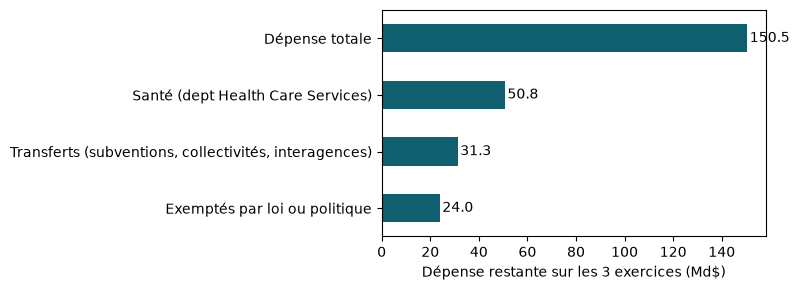

In [52]:
ax = tableau["reste (Md$)"].iloc[::-1].plot.barh(figsize=(8, 3), color="#0f5f6e")
ax.set_xlabel("Dépense restante sur les 3 exercices (Md$)")
ax.set_ylabel("")
for i, v in enumerate(tableau["reste (Md$)"].iloc[::-1]):
    ax.text(v + 1, i, f"{v:.1f}", va="center")
plt.tight_layout()
plt.show()

**Interprétation :** environ **24,0 Md$ sur trois exercices** restent dans le périmètre prioritaire, soit **15,9 %** du total. Les 84,1 % placés hors première vague demandent une analyse spécifique ; leur potentiel d'économie n'est pas mesuré ici.

**Décision :** poursuivre sur ces 24,0 Md$, sans les qualifier de montant intégralement négociable.

### 4.4 Le périmètre est-il stable d’un exercice à l’autre ?

In [53]:
total_par_exercice = df.groupby("fiscal_year")["total_price"].sum() / 1e9
par_exercice = df[perimetre].groupby("fiscal_year")["total_price"].sum() / 1e9

pd.DataFrame({
    "total (Md$)": total_par_exercice,
    "adressable (Md$)": par_exercice,
    "part adressable (%)": par_exercice / total_par_exercice * 100,
}).round(1)

,total (Md$),adressable (Md$),part adressable (%)
fiscal_year,,,
2012-2013,61.7,6.0,9.7
2013-2014,42.3,7.5,17.8
2014-2015,46.5,10.5,22.5


**Interprétation :** le périmètre passe de 6,0 à 7,5 puis 10,5 Md$, alors que le total passe de 61,7 à 42,3 puis 46,5 Md$. La série est trop courte et hétérogène pour une prévision fiable.

**Décision :** examiner les départements et les grosses commandes qui expliquent la hausse.

In [54]:
(df[perimetre]
 .pivot_table(index="department_name", columns="fiscal_year", values="total_price", aggfunc="sum")
 .div(1e9)
 .assign(total=lambda t: t.sum(axis=1))
 .sort_values("total", ascending=False)
 .head(5)
 .round(2))

fiscal_year,2012-2013,2013-2014,2014-2015,total
department_name,,,,
"Corrections and Rehabilitation, Department of",0.84,1.79,1.05,3.68
"High Speed Rail Authority, California",0.28,0.58,2.50,3.36
"Transportation, Department of",0.92,1.00,1.02,2.94
Correctional Health Care Services,0.56,0.59,0.81,1.96
"State Hospitals, Department of",0.33,0.59,0.53,1.45


**Interprétation :** la High Speed Rail Authority passe de 0,28 à 2,50 Md$. Mais Corrections varie aussi de 0,84 à 1,79 puis 1,05 Md$ : les autres départements ne sont pas tous stables.

**Décision :** ne pas attribuer toute la variation à un seul projet ; conserver la moyenne et le dernier exercice comme deux bases distinctes.

In [55]:
lignes_perimetre = df[perimetre]

part_top10 = lignes_perimetre.groupby("fiscal_year")["total_price"].apply(lambda s: s.nlargest(10).sum() / s.sum())
print("Part des 10 plus grosses lignes du périmètre :")
print(part_top10.map("{:.0%}".format).to_string())

lignes_perimetre.nlargest(5, "total_price")[["fiscal_year", "department_name", "supplier_name", "total_price"]]

Part des 10 plus grosses lignes du périmètre :
fiscal_year
2012-2013    17%
2013-2014    24%
2014-2015    34%


,fiscal_year,department_name,supplier_name,total_price
187014,2014-2015,"High Speed Rail Authority, California",Unknown,1.365336e+09
126255,2014-2015,"High Speed Rail Authority, California",Unknown,7.000000e+08
4848,2014-2015,Franchise Tax Board,CGI,3.989373e+08
229977,2013-2014,"Corrections and Rehabilitation, Department of",Hensel Phelps Construction Co,3.309654e+08
152648,2014-2015,Correctional Health Care Services,"MANAGEMENT SOLUTION, LLC",2.990939e+08


Les 10 plus grosses lignes pèsent 17 % / 24 % / 34 % du périmètre, selon l’exercice. Les 2 plus grosses lignes (1,37 et 0,70 Md$, en 2014-2015) sont de la High Speed Rail et ont pour fournisseur… « Unknown ». Les deux problèmes se rejoignent.

### 4.5 Sensibilité : et si mes règles sont fausses ?

In [56]:
segment_sante = (df["normalized_unspsc"] // 1_000_000) == 85

scenarios = {
    "Base (santé dept + transferts + exemptés)": sante_programmes | transferts | exemptes,
    "Santé définie par le segment UNSPSC 85": segment_sante | transferts | exemptes,
    "On garde les exemptés dans le périmètre": sante_programmes | transferts,
    "On garde les transferts dans le périmètre": sante_programmes | exemptes,
    "On retire seulement la santé": sante_programmes,
    "Aucune exclusion": pd.Series(False, index=df.index),
}

sensibilite = pd.Series(
    {nom: df.loc[~exclu, "total_price"].sum() / 1e9 for nom, exclu in scenarios.items()},
    name="Périmètre sur 3 exercices (Md$)",
)
sensibilite.round(1)

Base (santé dept + transferts + exemptés)     24.0
Santé définie par le segment UNSPSC 85        21.3
On garde les exemptés dans le périmètre       31.3
On garde les transferts dans le périmètre     28.3
On retire seulement la santé                  50.8
Aucune exclusion                             150.5
Name: Périmètre sur 3 exercices (Md$), dtype: float64

**Interprétation :** les variantes proches de la règle centrale donnent **21,3 à 31,3 Md$**. L'ensemble des scénarios testés va toutefois jusqu'à **150,5 Md$** ; retirer seulement la santé laisse **50,8 Md$**. La fourchette 21–31 ne résume donc pas tous les tests. Aucun scénario ne démontre l'impossibilité de négocier les montants exclus.

**Décision :** garder la règle centrale pour organiser la première vague et faire valider les exclusions. Les scénarios sont des hypothèses de périmètre, pas des intervalles de confiance.

### 4.6 « 5 % de quoi ? »

In [57]:
bases = ["Moyenne des 3 exercices", "Dernier exercice (2014-2015)"]

total_ref = pd.Series([total_par_exercice.mean(), total_par_exercice.iloc[-1]], index=bases)
adressable_ref = pd.Series([par_exercice.mean(), par_exercice.iloc[-1]], index=bases)
objectif = 0.05 * total_ref

pd.DataFrame({
    "Dépense totale (Md$)": total_ref,
    "Objectif 5 % (Md$)": objectif,
    "Périmètre adressable (Md$)": adressable_ref,
    "Effort requis (% du périmètre)": objectif / adressable_ref * 100,
}).round(1)

,Dépense totale (Md$),Objectif 5 % (Md$),Périmètre adressable (Md$),Effort requis (% du périmètre)
Moyenne des 3 exercices,50.2,2.5,8.0,31.4
Dernier exercice (2014-2015),46.5,2.3,10.5,22.2


**Interprétation :** si l'objectif porte sur le total, l'effort requis sur le seul périmètre prioritaire serait de **22 à 31 %**. C'est une exigence élevée, dont la faisabilité n'est pas démontrée. Si l'objectif portait seulement sur le périmètre prioritaire, il serait de 0,4 à 0,5 Md$ ; ce serait **un autre objectif**, à faire approuver.

**Décision :** conserver les 5 % du total comme cible et chiffrer explicitement l'écart restant après les leviers proposés.

**Interprétation :** 24,0 Md$ de commandes historiques constituent la première vague de revue. Leur récurrence, leurs échéances et leur caractère payé ou engagé restent inconnus.

**Décision :** retenir **8,0 Md$/an** (moyenne des trois exercices) comme proxy de travail, et **10,5 Md$** (dernier exercice) comme variante de référence, sans présenter l'une comme une prévision ni l'autre comme une borne haute probabiliste. Aucune économie n'est encore démontrée.

### 4.7 Contrôles complémentaires du périmètre

**Intérêt :** vérifier la réconciliation et le poids des fournisseurs non identifiés, puis séparer les montants des projets ferroviaires.

In [58]:
a = df.loc[perimetre].copy()
a["fournisseur_inconnu"] = (a["supplier_name"].isna() |
    a["supplier_name"].fillna("").str.casefold().isin(["unknown", "inconnu"]) |
    a["supplier_code"].isna() | a["supplier_code"].eq(0))
a["rail"] = a["department_name"].eq("High Speed Rail Authority, California")
assert np.isclose(df.loc[~perimetre, "total_price"].sum() + a["total_price"].sum(), depense_totale)
qualite = a.groupby(["rail", "fournisseur_inconnu"], dropna=False)["total_price"].agg(["size", "sum"])
qualite["M$"] = qualite.pop("sum") / 1e6
display(qualite.round(2))

size        M$
rail  fournisseur_inconnu                  
False False                293072  20117.82
      True                   3302    486.27
True  False                   349   1224.25
      True                     17   2138.00

**Interprétation :** le tableau distingue quatre groupes sans chevauchement. « Unknown » n'est pas une entreprise ; son agrégation donnerait une concentration artificielle. Le ferroviaire correspond à des projets dont le calendrier ne peut pas être annualisé comme des fournitures récurrentes.

**Décision :** garder ces montants dans le diagnostic, mais les placer en validation préalable avant tout scénario de négociation.

## 5. Où agir en priorité ?
### 5.1 Familles et départements

**Intérêt :** identifier les enjeux monétaires avant de chercher des anomalies. Une forte dépense est un enjeu à examiner, pas une preuve de surcoût.

,titre indicatif,lignes,part,part_cumulée,M$/an (proxy)
segment_code,,,,,
81,Engineering and Research and Technology Based ...,13821,0.147,0.147,1172.213
80,Management and Business Professionals and Admi...,3434,0.140,0.287,1121.400
85,Healthcare Services,2360,0.120,0.407,955.188
77,Environmental Services,551,0.093,0.499,740.012
93,Politics and Civic Affairs Services,3457,0.068,0.567,540.524
43,Information Technology Broadcasting and Teleco...,30544,0.065,0.632,521.115
72,Building and Facility Construction and Mainten...,5771,0.055,0.688,443.338
25,Commercial and Military and Private Vehicles a...,10545,0.024,0.712,195.289
92,National Defense and Public Order and Security...,1252,0.023,0.736,187.435


,lignes,part,part_cumulée,M$/an (proxy)
department_name,,,,
"Corrections and Rehabilitation, Department of",54811,0.153,0.153,1225.794
"High Speed Rail Authority, California",366,0.140,0.294,1120.748
"Transportation, Department of",14088,0.123,0.416,979.914
Correctional Health Care Services,31218,0.082,0.498,653.632
"State Hospitals, Department of",17378,0.061,0.559,484.400
"Water Resources, Department of",26908,0.052,0.610,412.031
"General Services, Department of",10299,0.045,0.655,358.102
Health & Human Services Agency,404,0.026,0.681,209.282
"Forestry and Fire Protection, Department of",22382,0.024,0.705,188.239


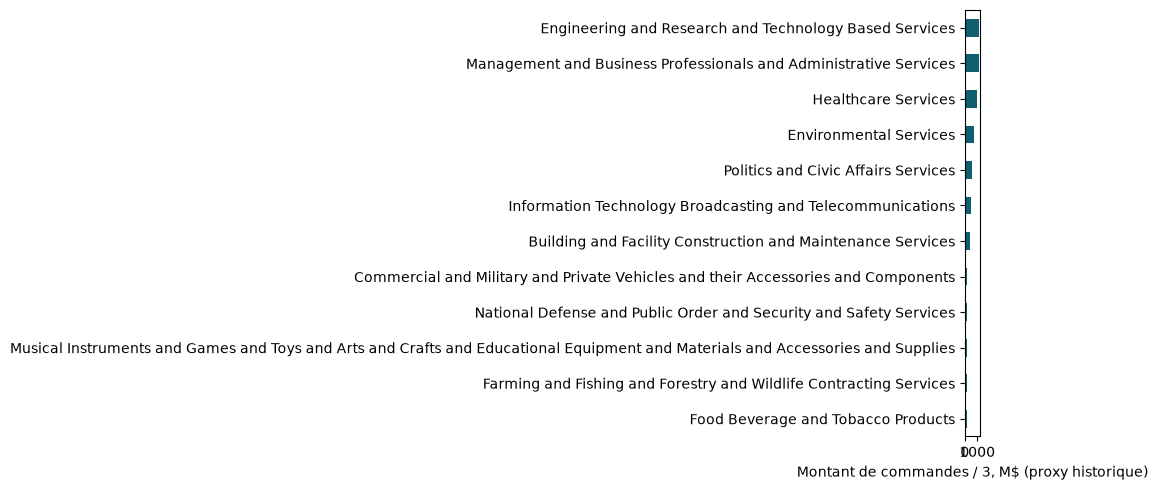

In [59]:
a["segment_code"] = (a["normalized_unspsc"] // 1_000_000).astype("Int64").astype("string").fillna("Non classé")
# Code en priorité ; titre descriptif le plus fréquent, sans affecter le regroupement.
titres = a.dropna(subset=["segment_title"]).groupby("segment_code")["segment_title"].agg(lambda x: x.mode().iloc[0])
def top_depense(data, cle, n=12):
    t = data.groupby(cle, dropna=False)["total_price"].agg(lignes="size", montant="sum").sort_values("montant", ascending=False)
    t["part"] = t["montant"] / data["total_price"].sum()
    t["part_cumulée"] = t["part"].cumsum()
    t["M$/an (proxy)"] = t.pop("montant") / 3e6
    return t.head(n)
segments = top_depense(a, "segment_code")
segments.insert(0, "titre indicatif", segments.index.map(titres).fillna("Non renseigné"))
display(segments.round(3))
departements = top_depense(a, "department_name")
display(departements.round(3))
ax = segments.set_index("titre indicatif")["M$/an (proxy)"].iloc[::-1].plot.barh(figsize=(10, 5), color="#0f5f6e")
ax.set_xlabel("Montant de commandes / 3, M$ (proxy historique)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Lecture chiffrée :** les trois premiers segments représentent 40,7 % du périmètre. Les premières familles sont Engineering and Research and Technology Based Services, Management and Business Professionals and Administrative Services, Healthcare Services.

**Interprétation :** les tableaux donnent le poids et le cumul des premières familles et des départements. La priorité monétaire doit être croisée avec la faisabilité contractuelle, la criticité du service et la récurrence ; elle ne suffit pas à fixer un taux d'économie.

**Décision :** présenter les principales familles aux responsables concernés et demander le détail des marchés. Les segments UNSPSC sont trop larges pour comparer directement des prix unitaires.

### 5.2 Des commandes identifiables, des fournisseurs traités avec prudence

**Intérêt :** éviter de confondre un numéro réutilisé dans plusieurs départements avec une commande unique et de fusionner automatiquement des fournisseurs différents.

In [60]:
cles_commande = ["department_name", "fiscal_year", "purchase_order_number"]
a["commande_id"] = pd.factorize(pd.MultiIndex.from_frame(a[cles_commande]))[0]
a["fournisseur_id"] = a["supplier_code"].astype("Int64").astype("string")
a.loc[a["fournisseur_inconnu"], "fournisseur_id"] = pd.NA
collisions = df.groupby("purchase_order_number")["department_name"].nunique().gt(1).sum()
print("Numéros de commande utilisés dans plusieurs départements :", collisions)
commandes = a.groupby(cles_commande, dropna=False).agg(montant=("total_price", "sum"), lignes=("total_price", "size"))
display(commandes.nlargest(12, "montant").assign(**{"M$": lambda t:t["montant"]/1e6}).drop(columns="montant").round(2))
connus = a.loc[~a["fournisseur_inconnu"]]
fournisseurs = connus.groupby("fournisseur_id").agg(nom=("supplier_name", "first"), montant=("total_price", "sum"), commandes=("commande_id", "nunique"))
fournisseurs["M$/an (proxy)"] = fournisseurs.pop("montant") / 3e6
display(fournisseurs.nlargest(12, "M$/an (proxy)").round(2))
print(f"Part du périmètre sans fournisseur identifié : {a.loc[a.fournisseur_inconnu,'total_price'].sum()/a.total_price.sum():.1%}")

Numéros de commande utilisés dans plusieurs départements : 2957


lignes  \
department_name                               fiscal_year purchase_order_number           
High Speed Rail Authority, California         2014-2015   HSR13-57                    1   
                                                          HSR14-66                    1   
Franchise Tax Board                           2014-2015   C1100017                    4   
Corrections and Rehabilitation, Department of 2013-2014   5600004334                  1   
Correctional Health Care Services             2014-2015   12-00501                    1   
                                                          12-00501-02                 1   
High Speed Rail Authority, California         2013-2014   HSR06-0001 #2               1   
Transportation, Department of                 2013-2014   59A0040                     1   
Finance, Department of                        2013-2014   FI$Cal 021-11               4   
High Speed Rail Authority, California         2012-2013   HSR12-06                    1   
Health & Human Services Agency                2014-2015   18104                       6   
Corrections and Rehabilitation, Department of 2013-2014   5600004382                  1   

                                                                                      M$  
department_name                               fiscal_year purchase_order_number           
High Speed Rail Authority, California         2014-2015   HSR13-57               1365.34  
                                                          HSR14-66                700.00  
Franchise Tax Board                           2014-2015   C1100017                401.24  
Corrections and Rehabilitation, Department of 2013-2014   5600004334              330.97  
Correctional Health Care Services             2014-2015   12-00501                299.09  
                                                          12-00501-02             299.09  
High Speed Rail Authority, California         2013-2014   HSR06-0001 #2           295.00  
Transportation, Department of                 2013-2014   59A0040                 239.50  
Finance, Department of                        2013-2014   FI$Cal 021-11           225.99  
High Speed Rail Authority, California         2012-2013   HSR12-06                225.90  
Health & Human Services Agency                2014-2015   18104                   202.10  
Corrections and Rehabilitation, Department of 2013-2014   5600004382              168.76

,nom,commandes,M$/an (proxy)
fournisseur_id,,,
1748084,"MANAGEMENT SOLUTION, LLC",4,199.40
1012653,Hensel Phelps Construction Co,3,151.48
1000330,CGI,4,148.93
1034419,Calif State Office of Systems Integration,5,112.87
1040238,T.Y. Lin International,6,107.26
1732187,"Parsons Brinckerhoff, Inc.",7,104.23
1455,A I M ENTERPRISES,5,92.88
1000446,ACCENTURE,5,92.46
1068480,Intuitive Health Services,46,78.82


Part du périmètre sans fournisseur identifié : 10.9%


**Interprétation :** les grands marchés constituent des dossiers concrets de revue. Le code fournisseur évite des fusions hasardeuses, mais peut séparer une même entreprise sous plusieurs codes : les rangs sont donc indicatifs. La clé département–exercice–numéro réduit les collisions ; elle peut séparer un même marché pluriannuel entre exercices.

**Décision :** utiliser cette clé pour les contrôles, conserver les codes fournisseurs et exclure « Unknown » des classements d'entreprises. Ne pas déduire un pouvoir de négociation d'un simple rang fournisseur.

### 5.3 Portefeuilles d'action sans double compte

**Intérêt :** affecter chaque commande à une seule action principale pour ne pas additionner plusieurs économies sur les mêmes achats.

**Hypothèses de tri :** validation préalable pour le ferroviaire, une identité fournisseur inconnue, un montant manquant, une urgence ou les programmes CRP/State Programs ; revue contractuelle pour une commande nette ≥ 10 M$ ; sinon méthodes non concurrentielles explicites, contrats mutualisés, puis autres achats. Le seuil de 10 M$ sert au tri des dossiers et n'est pas un seuil réglementaire.

In [61]:
validation = a.groupby("commande_id")["fournisseur_inconnu"].transform("any") | a.groupby("commande_id")["rail"].transform("any")
validation |= a["acquisition_method"].isin(["Emergency Purchase", "CRP", "State Programs"]).groupby(a["commande_id"]).transform("any")
validation |= a["total_price"].isna().groupby(a["commande_id"]).transform("any")
montant_commande = a.groupby("commande_id")["total_price"].transform("sum")
non_concurrentiel = a["acquisition_method"].isin(["NCB", "Non-Competitive Bid", "Special Category Request (SCR)", "Special Category Request", "LCB", "Limited Competitive Bidding"])
mutualise = a["acquisition_method"].isin(["Statewide Contract", "WSCA/Coop", "CMAS", "California Multiple Award Schedules", "Master Purchase/Price Agreement", "Master Service Agreement", "Master Rental Agreement", "State Price Schedule", "Software License Program"])
non_concurrentiel = non_concurrentiel.groupby(a["commande_id"]).transform("any")
mutualise = mutualise.groupby(a["commande_id"]).transform("any")
a["portefeuille"] = np.select([validation, montant_commande.ge(10e6), non_concurrentiel, mutualise],
    ["0. Validation préalable", "1. Grands marchés", "2. Revue du non-concurrentiel", "3. Contrats mutualisés"],
    default="4. Autres achats")
assert a.groupby("commande_id")["portefeuille"].nunique().eq(1).all()
portefeuille = a.groupby("portefeuille")["total_price"].sum().to_frame("sur 3 ans ($)")
portefeuille["M$/an (proxy)"] = portefeuille["sur 3 ans ($)"] / 3e6
assert np.isclose(portefeuille["sur 3 ans ($)"].sum(), a["total_price"].sum())
display(portefeuille.round(2))
display(pd.crosstab(a["acquisition_method"], a["portefeuille"]))

,sur 3 ans ($),M$/an (proxy)
portefeuille,,
0. Validation préalable,5.363213e+09,1787.74
1. Grands marchés,8.875866e+09,2958.62
2. Revue du non-concurrentiel,4.126932e+08,137.56
3. Contrats mutualisés,2.303781e+09,767.93
4. Autres achats,7.010779e+09,2336.93


portefeuille,0. Validation préalable,1. Grands marchés,2. Revue du non-concurrentiel,3. Contrats mutualisés,4. Autres achats
acquisition_method,,,,,
CMAS,84,0,0,3174,0
CRP,349,0,0,0,0
Emergency Purchase,9887,0,0,0,0
Fair and Reasonable,1221,24,0,2,24051
Formal Competitive,507,751,0,2,16779
Informal Competitive,1648,87,0,110,79520
LCB,62,0,422,0,0
Master Purchase/Price Agreement,1,0,0,1527,0
Master Service Agreement,87,30,0,2128,0


**Interprétation :** les méthodes orientent le type de revue, sans mesurer leur efficacité. Un achat sans concurrence peut être justifié par l'urgence ou l'unicité du besoin ; un contrat mutualisé peut déjà avoir obtenu un bon prix. Les différences brutes de prix entre méthodes ne démontrent aucun effet causal.

**Décision :** grands marchés → échéances et clauses ; non-concurrentiel → justification et alternatives autorisées ; contrats mutualisés → conformité au catalogue et adoption ; autres achats → standardisation des références et besoins. Aucun changement ne doit dégrader la disponibilité ou la qualité du service.

## 6. Peut-on objectiver des écarts de prix ?
### 6.1 Comparer des références aussi proches que possible

**Intérêt :** chercher un signal vérifiable sur les biens, sans assimiler des articles d'un même segment à des produits identiques.

**Règles :** biens IT ou non-IT, prix et quantités positifs, prix unitaire ≥ 1 $, fournisseur identifié, quantité > 1, présence d’un identifiant alphanumérique de modèle/référence, nom et description exacts après normalisation de casse/espaces, UNSPSC valide de 8 chiffres, même exercice et quantité dans une même tranche de facteur 2. Au moins trois commandes et deux fournisseurs par groupe. Le filtre ≥ 1 $ limite les effets d'arrondi, au prix d'une couverture plus faible. Aucun rapprochement flou.

In [62]:
b = a.loc[a["acquisition_type"].isin(["IT Goods", "NON-IT Goods"]) &
          a["total_price"].gt(0) & a["unit_price"].ge(1) & a["quantity"].gt(0) &
          ~a["fournisseur_inconnu"]].copy()
b = b.dropna(subset=["item_name", "item_description", "normalized_unspsc"])
b = b.loc[b["normalized_unspsc"].between(10_000_000, 99_999_999)]
b["article"] = b["item_name"].str.casefold()
b["description"] = b["item_description"].str.casefold()
# Les lignes à quantité 1 sont souvent des enveloppes ou lots, pas des unités.
# Une référence alphanumérique est un filtre heuristique, à faire confirmer par le métier.
texte_reference = b["article"] + " " + b["description"]
modele = texte_reference.str.contains(r"\b(?=[a-z0-9_-]*[a-z])(?=[a-z0-9_-]*\d)[a-z0-9_-]{4,}\b", regex=True, na=False)
b = b.loc[b["quantity"].gt(1) & modele & b["description"].str.len().ge(20)].copy()
b["tranche_q"] = np.floor(np.log2(b["quantity"])).astype(int)
b["prix_effectif"] = b["total_price"] / b["quantity"]
b = b.loc[np.isclose(b["prix_effectif"], b["unit_price"], rtol=.02, atol=.01)]
cles_prix = ["fiscal_year", "normalized_unspsc", "article", "description", "tranche_q"]
# Éviter que des lignes répétées d'une commande pèsent plusieurs fois dans le prix de référence.
ref = b.groupby(cles_prix + ["commande_id", "fournisseur_id"], dropna=False).agg(
    montant=("total_price", "sum"), quantite=("quantity", "sum")).reset_index()
ref["prix"] = ref["montant"] / ref["quantite"]
references = ref.groupby(cles_prix, dropna=False).agg(
    n_commandes=("commande_id", "nunique"), n_fournisseurs=("fournisseur_id", "nunique"),
    mediane=("prix", "median"))
references["q25"] = ref.groupby(cles_prix, dropna=False)["prix"].quantile(.25)
references = references.loc[references.n_commandes.ge(3) & references.n_fournisseurs.ge(2)]
comparaison = b.merge(references.reset_index(), on=cles_prix, how="inner", validate="many_to_one")
for nom in ["mediane", "q25"]:
    comparaison["ecart_" + nom] = ((comparaison["prix_effectif"]-comparaison[nom]).clip(lower=0)*comparaison["quantity"])
print("Groupes éligibles :", len(references), "| Lignes couvertes :", len(comparaison))
print(f"Couverture du périmètre : {comparaison.total_price.sum()/a.total_price.sum():.4%}")
print(f"Écart à la médiane sur 3 ans : {comparaison.ecart_mediane.sum()/1e6:.3f} M$")
print(f"Écart au 1er quartile sur 3 ans : {comparaison.ecart_q25.sum()/1e6:.3f} M$")
revue_prix = comparaison.sort_values("ecart_mediane", ascending=False)
display(revue_prix[["article", "department_name", "supplier_name", "quantity", "prix_effectif", "mediane", "n_commandes", "n_fournisseurs", "ecart_mediane"]].head(15).round(2))

Groupes éligibles : 22 | Lignes couvertes : 103
Couverture du périmètre : 0.0026%
Écart à la médiane sur 3 ans : 0.009 M$
Écart au 1er quartile sur 3 ans : 0.015 M$


,article,department_name,supplier_name,quantity,prix_effectif,mediane,n_commandes,n_fournisseurs,ecart_mediane
90,1/4 ton rock 3000lbs/cy,"Water Resources, Department of",TAYLOR EXCAVATING,900.0,38.10,31.17,6,2,6237.00
74,"tire, goodyear eagle rs-a, p235/55r17, clin 201","Highway Patrol, California",OK TIRE AND AUTOMOTIVE,125.0,111.01,105.30,5,2,713.75
101,"tire, goodyear eagle rs-a, p235/55r17, clin 201","Highway Patrol, California",OK TIRE AND AUTOMOTIVE,100.0,111.01,105.30,5,2,571.00
98,"tire, goodyear eagle rs-a, p245/55r18, clin 204","Highway Patrol, California",OK TIRE AND AUTOMOTIVE,70.0,128.95,123.37,3,2,390.60
73,"tire studdable,lt265/70r17 cooper discoverer s/t","Highway Patrol, California",Bruce's Tire Inc.,20.0,209.20,197.00,3,2,244.00
79,"tire, goodyear eagle rs-a, p235/55r17, clin 201","Highway Patrol, California",OK TIRE AND AUTOMOTIVE,20.0,111.01,105.30,3,2,114.20
94,"tire studdable,p265/70r17 cooper discoverer m+s","Highway Patrol, California",Bruce's Tire Inc.,50.0,129.00,127.00,4,3,100.00
76,"tire, goodyear eagle rs-a, p245/55r18, clin 204","Highway Patrol, California",OK TIRE AND AUTOMOTIVE,28.0,128.95,126.16,6,2,78.12
96,"tire, goodyear eagle rs-a, p245/55r18, clin 204","Highway Patrol, California",OK TIRE AND AUTOMOTIVE,25.0,128.95,126.16,6,2,69.75
80,"tire, goodyear eagle rs-a, p245/55r18, clin 204","Highway Patrol, California",OK TIRE AND AUTOMOTIVE,25.0,128.95,126.16,6,2,69.75


**Lecture chiffrée :** 103 lignes couvrent 0,0026 % du périmètre ; écart à la médiane 0,01 M$ sur trois ans, non qualifié comme économie.

**Interprétation :** un premier essai avec seuls libellés exacts et quantités comparables produisait des écarts dominés par des lignes « diesel », « trousers » ou « software » à quantité 1 : des enveloppes/ lots probablement non comparables. Ce chiffrage exploratoire a été abandonné. Les filtres supplémentaires ci-dessus réduisent ce risque sans démontrer une équivalence parfaite. La couverture et les écarts ci-dessus sont calculés uniquement sur les groupes éligibles. Même une description identique ne garantit pas une même unité, un même conditionnement, une même garantie ou un même niveau de service. Les prix bas peuvent être indisponibles pour les autres acheteurs. La médiane est moins sensible au minimum aberrant, mais n'est pas un prix garanti.

**Décision :** traiter les écarts comme une liste de vérification avec les acheteurs, **sans les extrapoler** à tout le périmètre et **sans les ajouter** aux scénarios de la partie 7 (risque de double compte). Si la couverture est faible, demander le référentiel article et les unités avant de complexifier la méthode.

## 7. Combien peut-on espérer économiser ?
### 7.1 Scénarios transparents et conditionnels

**Intérêt :** traduire les enjeux en ordres de grandeur, en distinguant les montants observés des paramètres non observables.

**Formule par portefeuille :** base historique annuelle × fraction revue et renégociable × réduction sur cette fraction × réalisation dans l'année. Le dernier facteur combine délai et mise en œuvre ; il ne mesure pas la récurrence, qui reste à confirmer. Aucun gain attribué au portefeuille en validation préalable.

**Hypothèses de travail, non estimées par le CSV :** scénario prudent = 25 % de base actionnable × 2 % de réduction × 50 % de réalisation ; central = 50 % × 5 % × 70 % ; ambitieux = 75 % × 8 % × 90 %. Paramètres communs pour éviter une précision artificielle. Montants bruts avant coûts de transition, à service constant ; aucune probabilité associée aux scénarios.

In [63]:
parametres = pd.DataFrame({"scenario":["Prudent", "Central", "Ambitieux"],
    "fraction_actionnable":[.25,.50,.75], "reduction":[.02,.05,.08], "realisation":[.50,.70,.90]}).set_index("scenario")
base_moyenne = a.groupby("portefeuille")["total_price"].sum()/3
base_derniere = a.loc[a.fiscal_year.eq("2014-2015")].groupby("portefeuille")["total_price"].sum().reindex(base_moyenne.index, fill_value=0)
def chiffrer(base):
    sortie = pd.DataFrame(index=base.index)
    for nom, p in parametres.iterrows():
        sortie[nom] = base * p.prod()
    sortie.loc[sortie.index.str.startswith("0.")] = 0.
    return sortie
estimations = chiffrer(base_moyenne)
display(parametres)
display((estimations/1e6).round(2).rename_axis("Gains conditionnels (M$/an)"))
objectif_total_moyen = depense_totale/3*.05
objectif_total_dernier = df.loc[df.fiscal_year.eq("2014-2015"),"total_price"].sum()*.05
comparaison_objectif = pd.DataFrame({"gain brut M$":estimations.sum()/1e6})
comparaison_objectif["% de la cible totale"] = estimations.sum()/objectif_total_moyen*100
comparaison_objectif["écart à la cible M$"] = (objectif_total_moyen-estimations.sum())/1e6
display(comparaison_objectif.round(2))
# Coûts inconnus : sensibilité illustrative, à remplacer par les devis et charges réels.
couts = pd.Series([0, 5e6, 20e6], name="coûts de mise en œuvre ($)")
display(pd.DataFrame({"coûts M$":couts/1e6, "central net M$":(estimations.Central.sum()-couts)/1e6}).round(2))

,fraction_actionnable,reduction,realisation
scenario,,,
Prudent,0.25,0.02,0.5
Central,0.50,0.05,0.7
Ambitieux,0.75,0.08,0.9


,Prudent,Central,Ambitieux
Gains conditionnels (M$/an),,,
0. Validation préalable,0.00,0.00,0.00
1. Grands marchés,7.40,51.78,159.77
2. Revue du non-concurrentiel,0.34,2.41,7.43
3. Contrats mutualisés,1.92,13.44,41.47
4. Autres achats,5.84,40.90,126.19


,gain brut M$,% de la cible totale,écart à la cible M$
Prudent,15.50,0.62,2493.13
Central,108.52,4.33,2400.11
Ambitieux,334.86,13.35,2173.78


,coûts M$,central net M$
0,0.0,108.52
1,5.0,103.52
2,20.0,88.52


**Lecture chiffrée :** 15,5 / 108,5 / 334,9 M$/an bruts ; le central couvre 4,3 % de la cible totale. Le solde à identifier est 2,40 Md$.

**Interprétation :** les gains sont conditionnels aux taux saisis ; ils ne constituent ni une économie constatée ni une garantie. La comparaison conserve la cible initiale de 5 % du total, et rend visible le déficit éventuel. Les coûts de transition peuvent réduire fortement un scénario prudent.

**Décision :** proposer un pilote et un budget de validation plutôt que promettre 5 %. Faire approuver les taux, les échéances, le coût et la récurrence des contrats avant de convertir ces scénarios en engagement budgétaire.

### 7.2 Les conclusions résistent-elles aux hypothèses ?

**Intérêt :** mesurer la sensibilité à la base temporelle, aux très grosses commandes et aux doublons. Le retrait des grosses commandes est un stress test, pas un nettoyage.

In [64]:
stress = {"Moyenne 3 exercices": estimations.sum(),
          "Dernier exercice": chiffrer(base_derniere).sum()}
montants_po = a.groupby("commande_id")["total_price"].sum()
ids_top10 = montants_po.nlargest(10).index
sans_top10 = a.loc[~a.commande_id.isin(ids_top10)]
sans_doublons = a.loc[~df.loc[perimetre].duplicated()]
for nom, data in [("Sans les 10 plus grosses commandes",sans_top10), ("Sans doublons exacts (test seulement)",sans_doublons)]:
    base = data.groupby("portefeuille")["total_price"].sum().reindex(base_moyenne.index, fill_value=0)/3
    stress[nom] = chiffrer(base).sum()
sensibilite_gains = pd.DataFrame(stress).T/1e6
display(sensibilite_gains.round(2))
print(f"Cible 5 % du total, moyenne : {objectif_total_moyen/1e6:,.1f} M$")
print(f"Cible 5 % du total, dernier exercice : {objectif_total_dernier/1e6:,.1f} M$")
assert estimations.loc["0. Validation préalable"].eq(0).all()
assert (estimations.Prudent <= estimations.Central).all()
assert (estimations.Central <= estimations.Ambitieux).all()

,Prudent,Central,Ambitieux
Moyenne 3 exercices,15.50,108.52,334.86
Dernier exercice,17.43,121.98,376.39
Sans les 10 plus grosses commandes,14.01,98.04,302.53
Sans doublons exacts (test seulement),15.47,108.30,334.20


Cible 5 % du total, moyenne : 2,508.6 M$
Cible 5 % du total, dernier exercice : 2,327.1 M$


**Interprétation :** changer de base ne crée pas d'information sur l'année suivante. La sensibilité quantifie une dépendance aux hypothèses ; elle ne donne pas un intervalle statistique. L'effet des doublons dans le périmètre et sur les gains doit être lu ici, plutôt que déduit de leur faible poids dans le total global.

**Décision :** communiquer les deux références temporelles et les trois scénarios, puis travailler sur un calendrier de renouvellement réel. Ne pas faire de bootstrap des lignes : ce serait ignorer les dépendances entre commandes et la nature contractuelle des gros montants.

### 7.3 Avec quel niveau de confiance ?

**Intérêt :** préciser ce que chaque résultat permet réellement de conclure.

| Résultat | Confiance | Justification et information manquante |
|---|---|---|
| Sommes et classements historiques | Élevée pour le fichier | Réconciliation effectuée ; exhaustivité et paiements non contrôlés |
| Périmètre de première vague | Moyenne | Règles explicites, validation métier nécessaire |
| Équivalence des articles et écarts de prix | Faible à moyenne | Filtres stricts, mais unités et conditions absentes |
| Gains à service constant | Faible avant validation | Taux, échéances, coûts et qualité du service non observés |
| Budget ou économie de l'année suivante | Faible | Trois exercices anciens, engagement pluriannuel et récurrence inconnus |

**Interprétation :** la principale incertitude est métier et contractuelle, pas une erreur d'échantillonnage. Le CSV est un historique administratif, pas un essai randomisé.

**Décision :** ne pas annoncer un niveau de confiance de 95 % injustifié. Classer les dossiers comme « signal », « validé par l'acheteur », « contractualisé », puis « réalisé et contrôlé ».

## 8. Recommandation à la directrice et plan de mise en œuvre

**Intérêt :** passer des constats à des actions dont l'effet pourra être vérifié.

| Priorité | Action | Responsable proposé | Livrable et critère de passage |
|---|---|---|---|
| Jours 1–15 | Valider cible, programmes et transferts ; rapprocher commandes et comptabilité | Direction Achats + Finance | Assiette budgétaire, règles d'exclusion et calendrier signés |
| Jours 1–30 | Identifier les fournisseurs inconnus et les grands projets | Données + acheteurs projets | Fournisseur réel, échéance, engagement annuel et possibilité de révision |
| Jours 15–45 | Examiner les grands marchés arrivant à échéance | Acheteurs familles + juridique | Dossiers chiffrés, alternatives autorisées, coûts de transition |
| Jours 30–60 | Vérifier les écarts de prix et usages des contrats mutualisés | Acheteurs + prescripteurs | Références et unités identiques ; pilote limité aux biens non critiques |
| Jours 60–90 | Mesurer et décider du déploiement | Finance + responsables du service | Gains nets validés et qualité au moins maintenue |

**Interprétation :** une baisse de montant entre deux années peut venir de la quantité, du mix d'articles ou de la fin d'un projet. Elle ne suffit pas à prouver une meilleure performance Achats.

**Décision :** mesurer le gain prix sur des références comparables : **(prix de référence validé − prix payé) × quantité réellement achetée − coûts de mise en œuvre**. Suivre séparément l'effet volume et le coût évité ; éviter les doubles comptes entre leviers. Finance valide la récurrence et l'impact budgétaire. Suivre taux de rupture, délais, retours/défauts et engagements de service ; fixer les seuils avant le pilote et interrompre tout changement qui dégrade le service.

In [65]:
print("RÉPONSE CHIFFRÉE, BASE MOYENNE HISTORIQUE")
print(f"Total / an : {depense_totale/3e9:.2f} Md$ ; cible 5 % : {objectif_total_moyen/1e6:.1f} M$")
print(f"Première vague / an : {a.total_price.sum()/3e9:.2f} Md$")
print(f"Base après validation préalable / an : {base_moyenne.loc[~base_moyenne.index.str.startswith('0.')].sum()/1e9:.2f} Md$")
print(f"Scénarios bruts conditionnels : {estimations.Prudent.sum()/1e6:.1f} / {estimations.Central.sum()/1e6:.1f} / {estimations.Ambitieux.sum()/1e6:.1f} M$")
print(f"Écart central à la cible totale : {(objectif_total_moyen-estimations.Central.sum())/1e6:.1f} M$")

RÉPONSE CHIFFRÉE, BASE MOYENNE HISTORIQUE
Total / an : 50.17 Md$ ; cible 5 % : 2508.6 M$
Première vague / an : 7.99 Md$
Base après validation préalable / an : 6.20 Md$
Scénarios bruts conditionnels : 15.5 / 108.5 / 334.9 M$
Écart central à la cible totale : 2400.1 M$


**Conclusion de décision :** les données permettent de prioriser une revue et de préparer un pilote, mais ne démontrent pas l'atteinte de 5 % sans dégrader le service. La première étape est de valider l'assiette budgétaire ; la seconde, de transformer les signaux en dossiers contractuels. Les montants calculés sont des scénarios historiques conditionnels, jamais une prévision garantie.